# Hypothesis Testing: Men's vs Women's Soccer Goals (Python)

**Question:** are more goals scored in women's international soccer matches than in men's?

**Scope:** official FIFA World Cup matches only (no qualifiers), played since 2002-01-01.

**Hypotheses** (significance level α = 10%):
- H₀: the mean number of goals in women's matches is the same as in men's.
- H₁: the mean number of goals in women's matches is **greater** than in men's (one-sided test).

**Tools:** Python (pandas, SciPy, Matplotlib).
**Data:** `women_results.csv` and `men_results.csv`, results of international matches.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

women = pd.read_csv("women_results.csv", parse_dates=["date"])
men = pd.read_csv("men_results.csv", parse_dates=["date"])

## 1. Filter World Cup matches since 2002 and calculate total goals

In [2]:
def world_cup_since_2002(df):
    wc = df[(df["tournament"] == "FIFA World Cup") & (df["date"] > "2002-01-01")].copy()
    wc["total_goals"] = wc["home_score"] + wc["away_score"]
    return wc

women_wc = world_cup_since_2002(women)
men_wc = world_cup_since_2002(men)

print(f"Women: {len(women_wc)} matches, {women_wc['total_goals'].mean():.2f} goals per match")
print(f"Men:   {len(men_wc)} matches, {men_wc['total_goals'].mean():.2f} goals per match")

Women: 200 matches, 2.98 goals per match
Men:   384 matches, 2.51 goals per match


## 2. Choose the right test: are goals normally distributed?
A t-test assumes normal data. Goals per match are counts, so I check the distribution first.

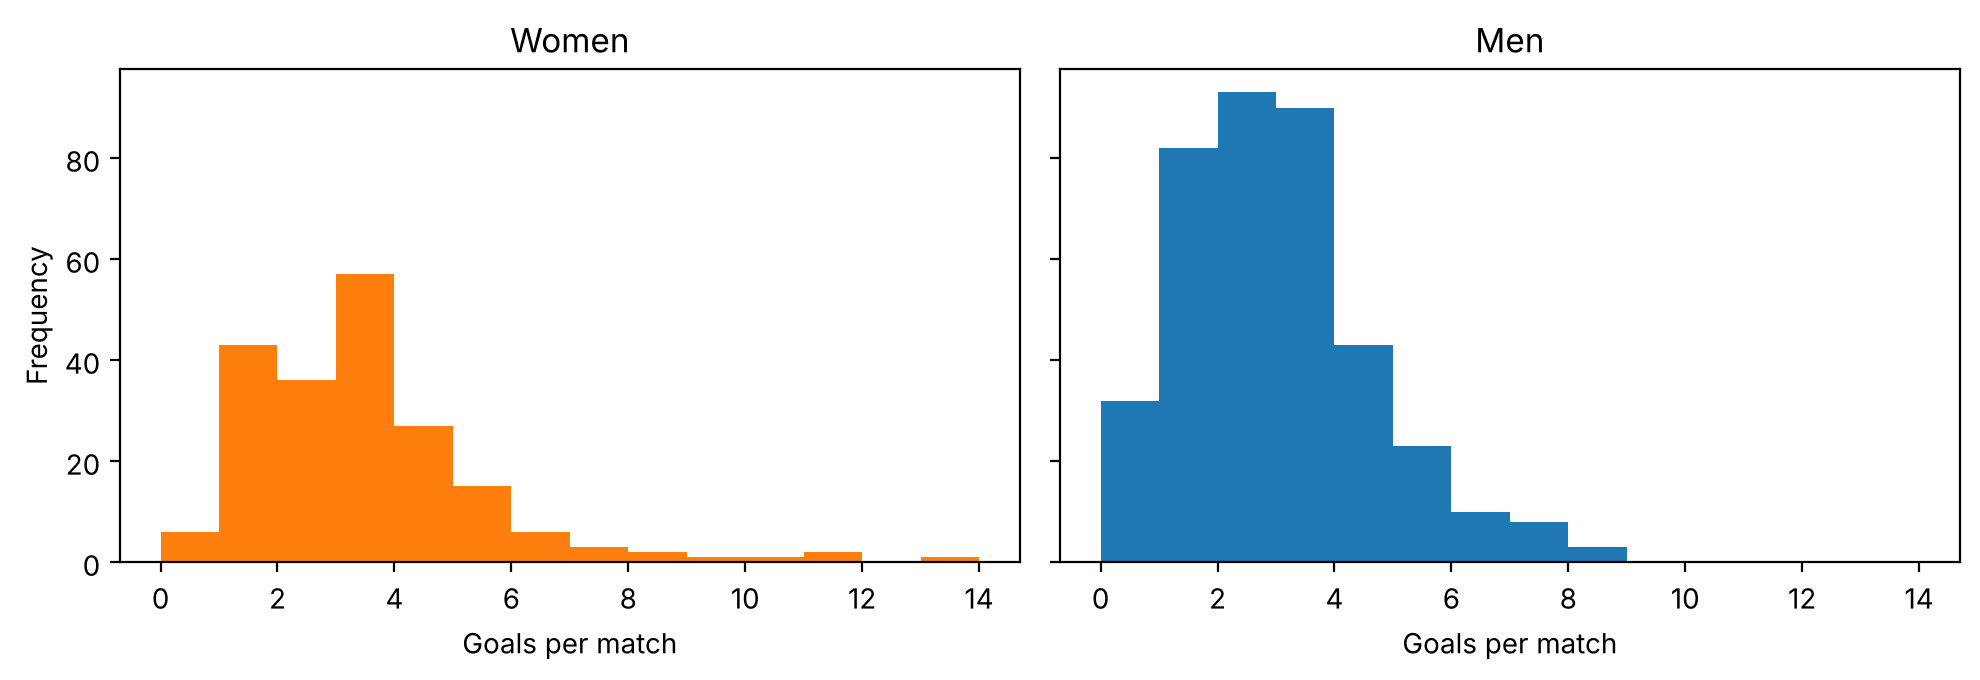

Shapiro-Wilk p-value (women): 3.8908294486369825e-13
Shapiro-Wilk p-value (men):   8.894988582231907e-13


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
women_wc["total_goals"].plot(kind="hist", bins=range(0, 15), ax=axes[0], title="Women", color="tab:orange")
men_wc["total_goals"].plot(kind="hist", bins=range(0, 15), ax=axes[1], title="Men", color="tab:blue")
for ax in axes:
    ax.set_xlabel("Goals per match")
plt.tight_layout()
plt.show()

print("Shapiro-Wilk p-value (women):", stats.shapiro(women_wc["total_goals"]).pvalue)
print("Shapiro-Wilk p-value (men):  ", stats.shapiro(men_wc["total_goals"]).pvalue)

Both distributions are right-skewed and the Shapiro-Wilk test rejects normality (p < 0.001), so I use a **non-parametric test: Mann-Whitney U**, one-sided (`alternative="greater"`).

## 3. Hypothesis test

In [4]:
alpha = 0.10

u_stat, p_val = stats.mannwhitneyu(women_wc["total_goals"], men_wc["total_goals"],
                                   alternative="greater")

result = "reject" if p_val <= alpha else "fail to reject"
result_dict = {"p_val": round(float(p_val), 4), "result": result}

print(f"U statistic: {u_stat:.0f}")
print(f"p-value: {p_val:.4f}")
result_dict

U statistic: 43273
p-value: 0.0051


{'p_val': 0.0051, 'result': 'reject'}

## Conclusion

The p-value (≈ 0.005) is far below the 10% significance level, so **we reject H₀**: there is strong statistical evidence that **more goals are scored in women's World Cup matches than in men's** (2.98 vs 2.51 goals per match on average since 2002).

Because goals are not normally distributed, a non-parametric test (Mann-Whitney U) is more appropriate here than a t-test.